#Growth Across Countries: Are Poorer Economies Catching Up?

##Table of Contents
1. [Setup](#scrollTo=aSetup0001&line=1&uniqifier=1)
2. [Description of the dataset](#scrollTo=bData00002&line=1&uniqifier=1)
3. [Description of the variables of interest](#scrollTo=cVars00003&line=1&uniqifier=1)
4. [Analytical roadmap](#scrollTo=dRoad00004&line=1&uniqifier=1)
5. [RQ 1: Has the growth gap between income groups narrowed or widened since 2000?](#scrollTo=eStudy0001&line=1&uniqifier=1)
    - Line Chart
6. [RQ 2: Which 10 countries had the highest average growth from 2000 to 2025?](#scrollTo=eStudy0002&line=1&uniqifier=1)
    - Horizontal bar chart
7. [RQ 3: In how many countries did the economy shrink each year?](#scrollTo=eStudy0003&line=1&uniqifier=1)
    - Area chart
8. [RQ 4: What was the typical growth rate of countries in 2024?](#scrollTo=eStudy0004&line=1&uniqifier=1)
    - Histogram
9. [RQ 5: Which region has the most stable growth, and which the most volatile?](#scrollTo=eStudy0005&line=1&uniqifier=1)
    - Box plot
10. [RQ 6: Which regions grew fastest in which years?](#scrollTo=eStudy0006&line=1&uniqifier=1)
    - Heatmap
11. [RQ 7: In how many years did Mexico grow faster than the world average?](#scrollTo=eStudy0007&line=1&uniqifier=1)
    - Pie chart
12. [RQ 8: Can a country's average growth in the 2000s predict its average growth in the 2010s? (Regression)](#scrollTo=eStudy0008&line=1&uniqifier=1)
    - Linear regression + scatter plot with line
13. [Final Conclusions](#scrollTo=fConcl0009&line=1&uniqifier=1)

#[Setup](#scrollTo=aToc000000&line=21&uniqifier=1)

In [3]:
file_path='https://raw.githubusercontent.com/A01178590/2039_class_blablabla/refs/heads/main/GDP%20Growth%20annual%20%25%20(6).csv'
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
df=pd.read_csv(file_path, skiprows=3)
df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,1.234335,3.493430,3.212471,1.229144,-23.940059,14.833692,10.607961,9.516360,6.810777,NaN
1,Africa Eastern and Southern,AFE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,0.418605,7.937089,5.624317,4.650349,5.138153,...,2.292501,2.678863,2.706207,1.935593,-2.930764,4.452643,3.668029,1.941382,2.787931,3.743016
2,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,2.260314,2.647003,1.189228,3.911603,-2.351101,-20.738839,-6.240172,2.266944,1.873193,NaN
3,Africa Western and Central,AFW,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,1.869593,3.726016,7.038172,5.364580,4.105660,...,0.176172,2.302761,2.899954,3.283142,-3.718793,2.545473,4.477108,3.644591,4.596183,4.600100
4,Angola,AGO,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.233077,-0.164689,-0.506698,-1.055234,-5.273491,1.090584,3.557492,1.320166,4.952679,3.133535


In [4]:
df.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
       '2023', '2024', '2025'],
      dtype='object')

In [5]:
favs=['Country Name','Country Code','2000','2001','2002','2003','2004','2005','2006','2007','2008','2009','2010','2011','2012','2013','2014','2015','2016','2017','2018','2019','2020','2021','2022','2023','2024','2025']

ndf=df[favs]
ndf.shape

(266, 28)

In [6]:
ndf=ndf.dropna()
ndf.shape

(231, 28)

Removing the rows with missing values leaves 231 of the 266 rows, so some countries and groups with missing years are not included in the analysis.

In [7]:
new_names={'Country Name':'country',
           'Country Code':'code'}
ndf=ndf.rename(columns= new_names)
ndf.head()

,country,code,2000,2001,2002,2003,2004,2005,2006,2007,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
1,Africa Eastern and Southern,AFE,3.180947,3.503347,3.916848,3.009269,5.634682,6.173729,6.637460,6.702363,...,2.292501,2.678863,2.706207,1.935593,-2.930764,4.452643,3.668029,1.941382,2.787931,3.743016
3,Africa Western and Central,AFW,3.811943,5.248525,9.943096,5.626390,8.071397,5.797495,5.287469,5.447340,...,0.176172,2.302761,2.899954,3.283142,-3.718793,2.545473,4.477108,3.644591,4.596183,4.600100
4,Angola,AGO,3.054624,4.205999,13.665689,3.487312,11.419863,14.154778,11.841818,13.002689,...,-0.233077,-0.164689,-0.506698,-1.055234,-5.273491,1.090584,3.557492,1.320166,4.952679,3.133535
5,Albania,ALB,7.462859,8.863731,4.628396,5.333264,5.266262,5.130822,6.018981,6.500093,...,3.908936,3.283176,3.671419,2.062578,-3.313756,8.969576,4.826801,4.015417,4.045928,3.788938
6,Andorra,AND,3.528362,8.119358,4.546362,8.694204,8.135676,5.397796,4.808689,1.553188,...,3.709678,0.346072,1.588765,2.015548,-11.183940,8.286779,9.564612,2.583555,3.849161,3.868035


In [8]:
years=ndf.columns[2:]
years

Index(['2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008',
       '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017',
       '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025'],
      dtype='object')

In [9]:
def type_cls(x):
  if x in ['AFE','AFW','ARB','CEB','CSS','EAP','EAR','EAS','ECA','ECS','EMU','EUU','FCV',
           'HIC','HPC','IBD','IBT','IDA','IDB','IDX','INX','LAC','LCN','LDC','LIC','LMC',
           'LMY','LTE','MEA','MIC','MNA','NAC','OED','OSS','PRE','PSS','PST','SAS','SSA',
           'SSF','SST','TEA','TEC','TLA','TMN','TSA','TSS','UMC','WLD']:
    return 'Aggregate'
  return 'Country'

In [10]:
type_cls('WLD')

'Aggregate'

In [11]:
ndf=ndf.copy()
ndf['row_type'] = ndf['code'].apply(type_cls)
ndf['row_type'].value_counts()

,count
row_type,
Country,183
Aggregate,48


In [12]:
cdf=ndf[ndf['row_type']=='Country'].copy()
cdf.shape

(183, 29)

## [Description of the dataset](#scrollTo=aToc000000&line=21&uniqifier=1)

This dataset comes from the World Bank's World Development Indicators and shows the annual GDP growth % of countries and groups of countries such as regions, income groups and the World. The original file covers from 1960 to 2025, but this analysis uses 2000 to 2025.

We use 28 variables: Country Name, Country Code and the years 2000 to 2025. One row represents one country or group, and each year column gives its GDP growth % for that year.

## [Description of the variables of interest](#scrollTo=aToc000000&line=21&uniqifier=1)

| Variable | Meaning | Type | Unit / Categories |
|---|---|---|---|
| country code | Name of the country or group of countries | Categorical (nominal) | Country names |
| code | Short code of each country or group, used to find specific rows | Categorical (nominal) | Country codes |
| 2000 ... 2025 | Annual GDP growth compared to the previous year. A negative value means the economy shrank. One column per year, so it is time series data | Numerical (continuous), time-related | % |
| row_type | It is a column that says if the row is a single country or a group | Categorical (binary) | Country, Aggregate |
| avg_growth | It is a column of the average GDP growth of each country from 2000 to 2025 | Numerical (continuous) | % |
| avg_early | It is a column of the average GDP growth of each country from 2000 to 2009 (explanatory variable X in the regression) | Numerical (continuous) | % |
| avg_late | It is a column of the average GDP growth of each country from 2010 to 2019 (outcome variable Y in the regression) | Numerical (continuous) | % |
| gap | It is a column of the difference in GDP growth: income group minus High income (Study 1), or Mexico minus the World (Study 7) | Numerical (continuous) | Percentage points |
| result | It is a column that says if Mexico grew above or below the world in each year, based on the gap | Categorical (binary) | Above and below world |
| resid | It is a column with the residual of the regression: real avg_late minus predicted avg_late | Numerical (continuous) | Percentage |

The years are kept as column names (2000 to 2025) because that is how the file comes, and each one represents the time variable.

## [Analytical roadmap](#scrollTo=aToc000000&line=21&uniqifier=1)

| Study | Research question | Study / Figure | Main insight |
|---|---|---|---|
| 1 | Has the growth gap between income groups narrowed or widened since 2000? | Line chart | The gap narrowed because the poorer groups slowed down (Low income: 3.22 to 0.85 pp) |
| 2 | Which 10 countries had the highest average growth from 2000 to 2025? | Horizontal bar chart | Guyana is first with about 10.8% |
| 3 | In how many countries did the economy shrink each year? | Area chart | 2020 was the worst year, with 147 of 183 countries shrinking |
| 4 | What was the typical growth rate of countries in 2024? | Histogram | The typical country grew about 3.4% |
| 5 | Which region has the most stable growth, and which the most volatile? | Box plot | North America is the most stable and Latin America & Caribbean the most volatile |
| 6 | Which regions grew fastest in which years? | Heatmap | 2020 was negative in all regions, and South Asia grew fastest |
| 7 | In how many years did Mexico grow faster than the world average? | Pie chart | Only 7 of 26 years (26.9%) |
| 8 | Can a country's average growth in the 2000s predict its average growth in the 2010s? | Linear Regression + scatter plot with line | A weak predictor: R² is about 5% |

# [RQ 1: Has the growth gap between income groups narrowed or widened since 2000?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** Subtract the growth of High income from the growth of each other income group in every year (gap) and compare the gap over time.

**Why this figure:** A line chart shows how values change over time so we can see if the gap goes up or down.

In [13]:
lic=ndf[ndf['code']=='LIC'][years].iloc[0]
lmc=ndf[ndf['code']=='LMC'][years].iloc[0]
umc=ndf[ndf['code']=='UMC'][years].iloc[0]
hic=ndf[ndf['code']=='HIC'][years].iloc[0]

gap_df=pd.DataFrame({'Low income': lic - hic,
                     'Lower middle income': lmc - hic,
                     'Upper middle income': umc - hic})
gap_df.head()

,Low income,Lower middle income,Upper middle income
2000,-1.135339,-0.292325,1.692500
2001,3.125389,2.823161,1.897293
2002,3.721047,2.244520,3.208901
2003,2.101965,3.151477,3.654382
2004,2.899786,4.013291,4.349710


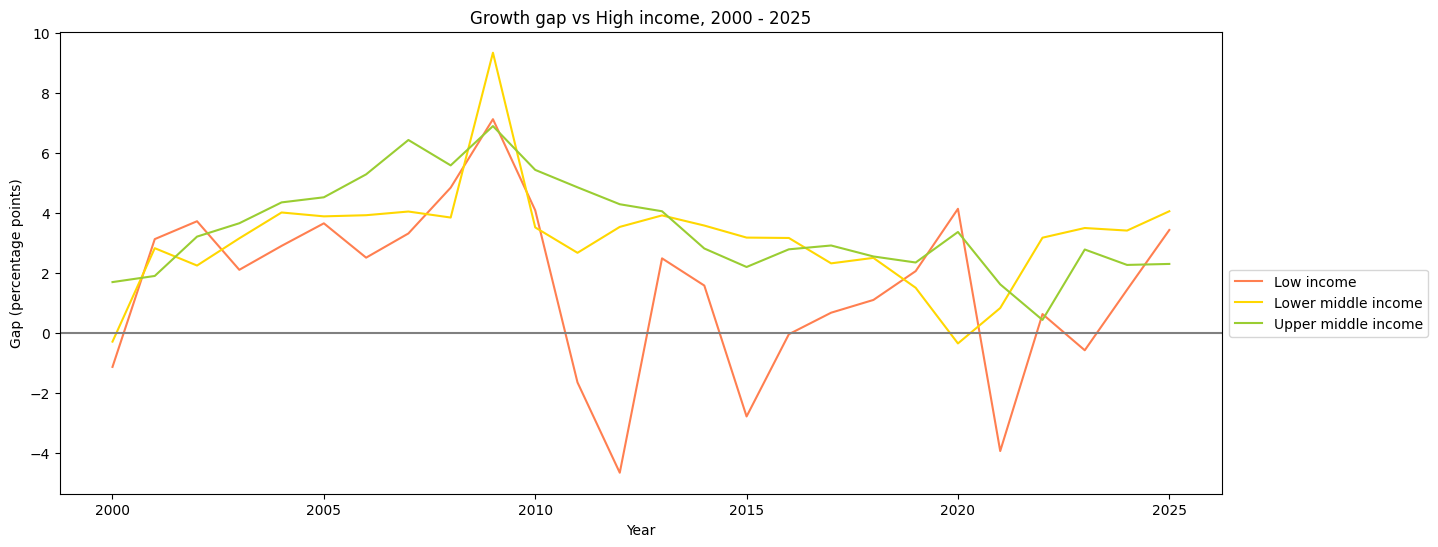

In [14]:
colors=['coral','gold','yellowgreen']

gap_df.plot(kind='line',
            figsize=(15,6),
            color = colors
            )
plt.axhline(0, color='gray')
plt.legend(bbox_to_anchor = (1,0.5))
plt.title('Growth gap vs High income, 2000 - 2025')
plt.xlabel('Year')
plt.ylabel('Gap (percentage points)')
plt.show()

In [42]:
#Where the numbers of the insights come from: average growth and average gap by period.
levels_df=pd.DataFrame({'Low income': lic,
                        'Lower middle income': lmc,
                        'Upper middle income': umc,
                        'High income': hic})

period_df=pd.DataFrame({'2000 - 2009': levels_df.loc['2000':'2009'].mean(),
                        '2010 - 2019': levels_df.loc['2010':'2019'].mean(),
                        '2020 - 2025': levels_df.loc['2020':'2025'].mean()})
period_df.round(2)

,2000 - 2009,2010 - 2019,2020 - 2025
Low income,5.20,2.42,2.67
Lower middle income,5.68,5.13,4.25
Upper middle income,6.33,5.56,3.94
High income,1.98,2.14,1.81


In [16]:
gap_period=pd.DataFrame({'2000 - 2009': gap_df.loc['2000':'2009'].mean(),
                         '2010 - 2019': gap_df.loc['2010':'2019'].mean(),
                         '2020 - 2025': gap_df.loc['2020':'2025'].mean()})
gap_period.round(2)

,2000 - 2009,2010 - 2019,2020 - 2025
Low income,3.22,0.28,0.85
Lower middle income,3.70,2.99,2.43
Upper middle income,4.35,3.42,2.13


<details open>
<summary><strong>Insights:</strong></summary>

1. **The gap narrowed.** Comparing 2020-2025 with 2000-2009, the growth gap vs High income fell from 3.22 to 0.85 pp for Low income, from 3.70 to 2.43 pp for Lower middle income and from 4.35 to 2.13 pp for Upper middle income.

</details>

# [RQ 2: Which 10 countries had the highest average growth from 2000 to 2025?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** Calculate the average growth of each country from 2000 to 2025 and rank the countries from 1 to 10.

**Why this figure:** A horizontal bar chart is the best way to compare and rank categories.

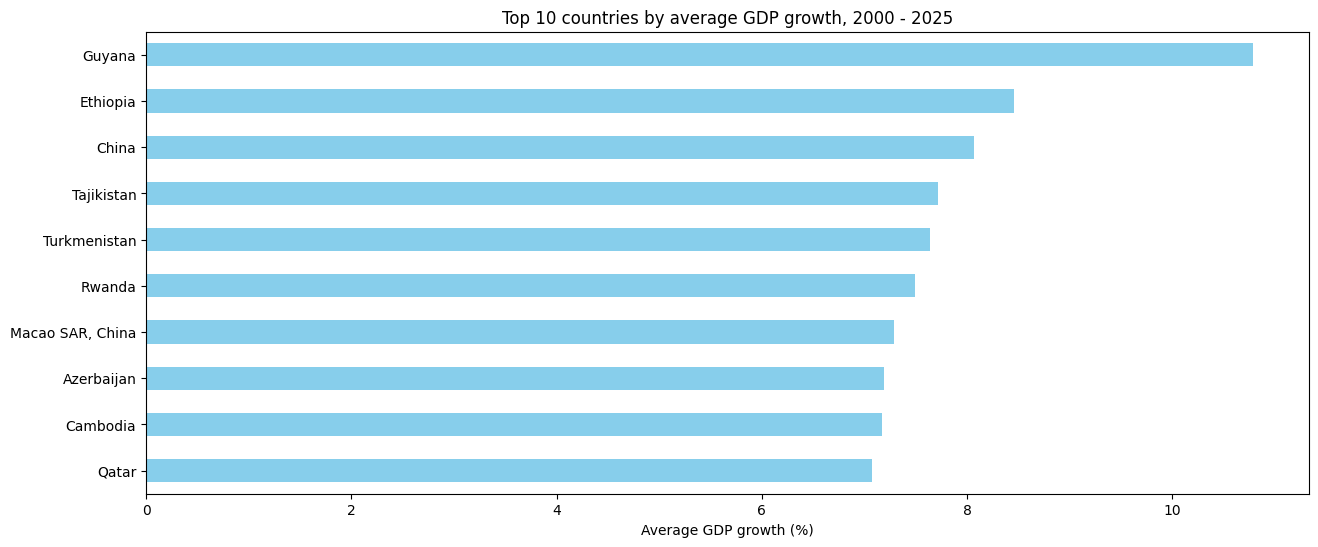

In [17]:
cdf['avg_growth']=cdf[years].mean(axis=1)

top10=cdf.sort_values('avg_growth').tail(10)

top10.plot(x='country',
           y='avg_growth',
           kind='barh',
           figsize=(15,6),
           color='skyblue',
           legend=False
           )
plt.title('Top 10 countries by average GDP growth, 2000 - 2025')
plt.xlabel('Average GDP growth (%)')
plt.ylabel('')
plt.show()

In [18]:
top10[['country','avg_growth']]

,country,avg_growth
200,Qatar,7.074651
123,Cambodia,7.169036
15,Azerbaijan,7.193347
146,"Macao SAR, China",7.286253
203,Rwanda,7.495390
235,Turkmenistan,7.635243
234,Tajikistan,7.720172
40,China,8.067042
72,Ethiopia,8.453437
94,Guyana,10.789026


In [19]:
cdf['avg_growth'].median()

3.3217144631538464

<details open>
<summary><strong>Insights:</strong></summary>

1. Guyana had the highest average growth with 10.78%.

2. All of the top 10 grew more than 7% a year on average.

</details>

# [RQ 3: In how many countries did the economy shrink each year?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** It is a count for each year of how many countries had negative growth.

**Why this figure:** An area chart shows how a count changes over time, and the crisis years are easy to see.

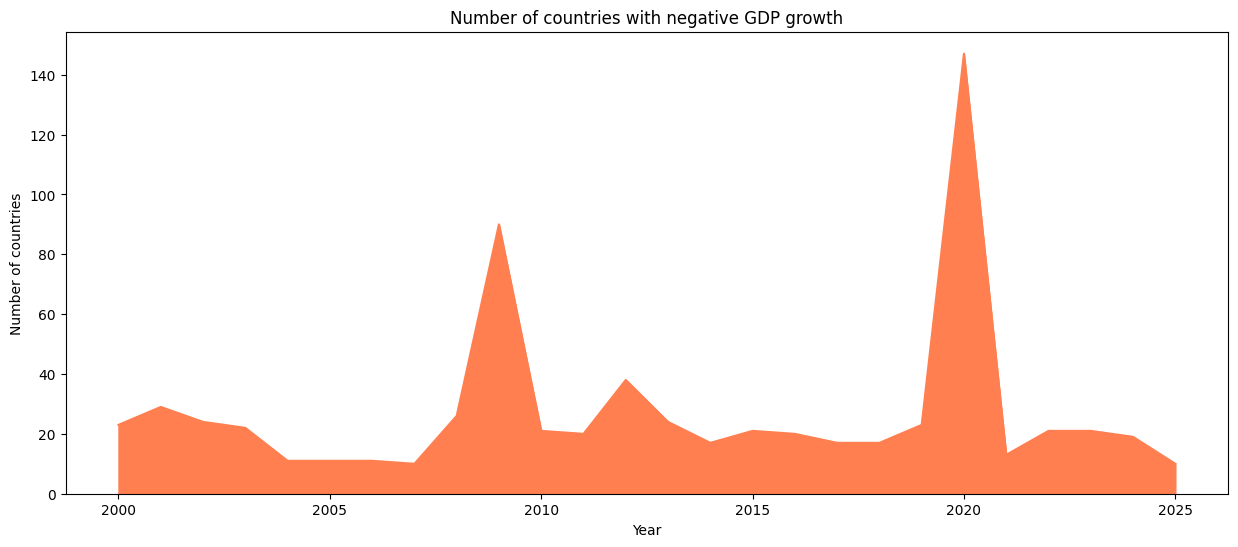

In [20]:
neg_counts=(cdf[years] < 0).sum()

neg_counts.plot(kind='area',
                figsize=(15,6),
                color='coral'
                )
plt.title('Number of countries with negative GDP growth')
plt.xlabel('Year')
plt.ylabel('Number of countries')
plt.show()

In [21]:
neg_counts.sort_values(ascending=False).head(3)

,0
2020,147
2009,90
2012,38


In [22]:
other_years=neg_counts.drop(['2009','2020'])
other_years.describe()

,0
count,24.000000
mean,19.541667
std,6.639665
min,10.000000
25%,16.000000
50%,20.500000
75%,23.000000
max,38.000000


<details open>
<summary><strong>Insights:</strong></summary>

1. 2020 was the worst year with 147 of 183 countries shrinking.

2. In every other year there were between 10 and 38 countries that had negative growth.

</details>

# [RQ 4: What was the typical growth rate of countries in 2024?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** Look at the growth of all countries in 2024 and see how the values are distributed.

**Why this figure:** A histogram shows the distribution of one numerical variable, so we can see what is normal and what is rare.

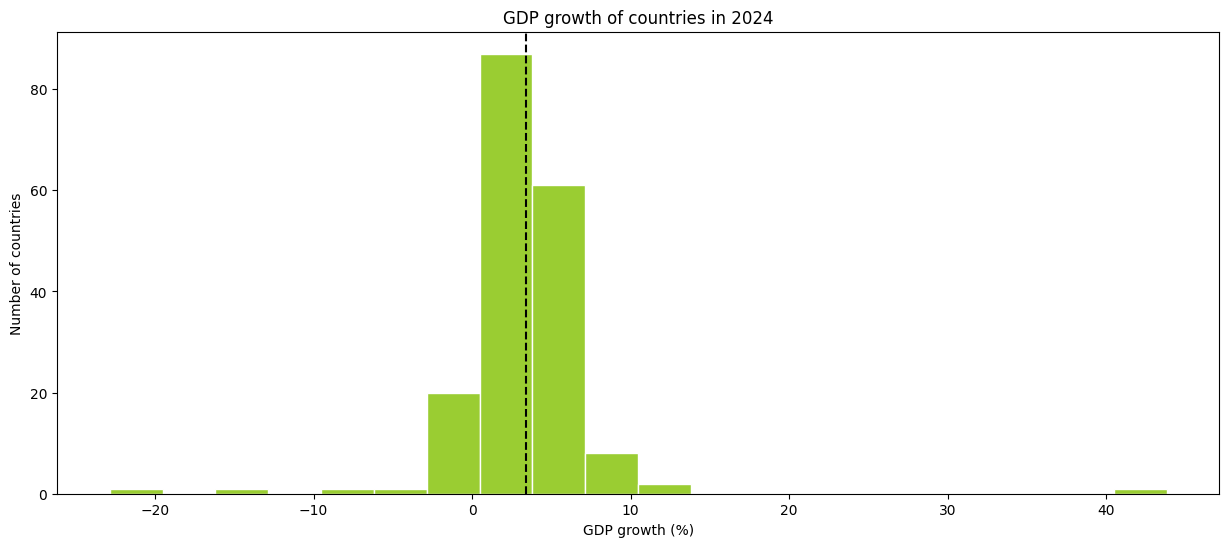

In [23]:
cdf['2024'].plot(kind='hist',
                 bins=20,
                 figsize=(15,6),
                 color='yellowgreen',
                 edgecolor='white'
                 )
plt.axvline(cdf['2024'].median(), color='black', linestyle='--')
plt.title('GDP growth of countries in 2024')
plt.xlabel('GDP growth (%)')
plt.ylabel('Number of countries')
plt.show()

In [24]:
cdf['2024'].describe()

,2024
count,183.000000
mean,3.238239
std,4.604090
min,-22.857327
25%,1.674964
50%,3.387090
75%,4.801430
max,43.819273


<details open>
<summary><strong>Insights:</strong></summary>

1. The typical country grew about 3.4% in 2024.

2. There are a cases that go from -22.9% to 43.8%.

</details>

# [RQ 5: Which region has the most stable growth and which the most volatile?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** Compare the yearly growth of each region from 2000 to 2025 and see how spread out it is (MENAAP = Middle East, North Africa, Afghanistan & Pakistan).

**Why this figure:** A box plot compares the median and the spread of several groups side by side.

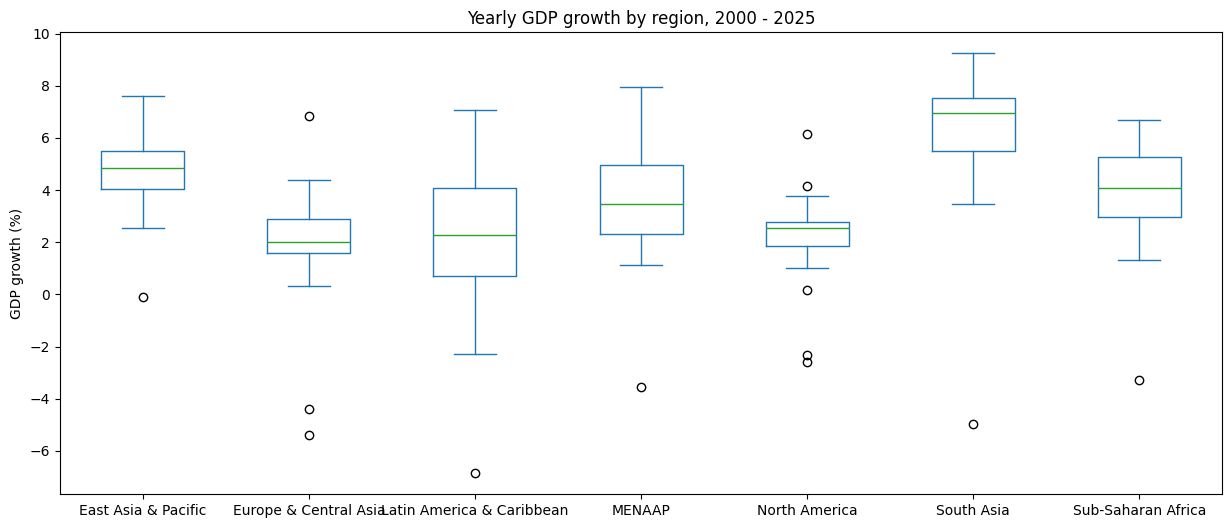

In [25]:
rdf=ndf[ndf['code'].isin(['EAS','ECS','LCN','MEA','NAC','SAS','SSF'])]
rdf=rdf.set_index('country')

region_names={'Middle East, North Africa, Afghanistan & Pakistan':'MENAAP'}
rdf.rename(index= region_names,
           inplace=True)

rdf[years].T.plot(kind='box',
                  figsize=(15,6)
                  )
plt.title('Yearly GDP growth by region, 2000 - 2025')
plt.ylabel('GDP growth (%)')
plt.show()

In [26]:
region_stats=rdf[years].T.describe().T
region_stats['iqr']=region_stats['75%'] - region_stats['25%']
region_stats[['50%','iqr']].round(2)

,50%,iqr
country,,
East Asia & Pacific,4.87,1.45
Europe & Central Asia,2.01,1.32
Latin America & Caribbean,2.29,3.39
MENAAP,3.45,2.66
North America,2.54,0.92
South Asia,6.94,2.04
Sub-Saharan Africa,4.08,2.27


<details open>
<summary><strong>Insights:</strong></summary>

1. North America was the most stable region because it has the smallest box and Latin America and Caribbean the most volatile because it has the biggest box.

2. South Asia had the highest typical growth with a median of about 6.9% and Europe & Central Asia the lowest with about 2.0%.

</details>

# [RQ 6: Which regions grew fastest in which years?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** Show the growth of each region in each year.

**Why this figure:** A heatmap shows two categories (region and year) and one number (growth) with colors, so changes are easy to spot.

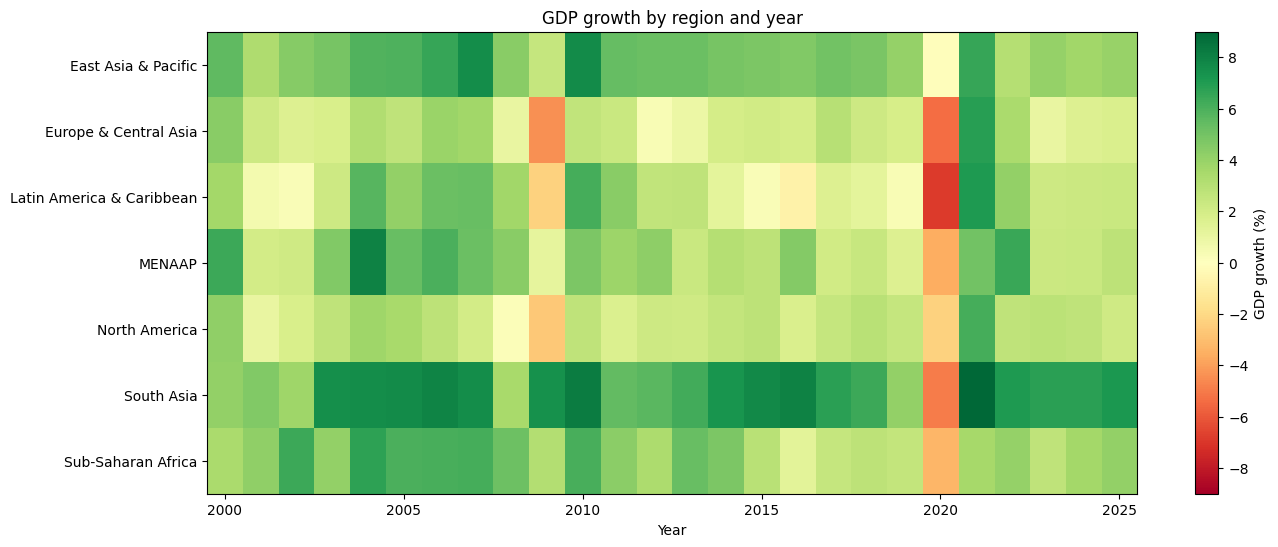

In [27]:
plt.figure(figsize=(15,6))
plt.imshow(rdf[years],
           aspect='auto',
           cmap='RdYlGn',
           vmin=-9,
           vmax=9
           )
plt.colorbar(label='GDP growth (%)')
plt.yticks(range(7), rdf.index)
plt.xticks([0,5,10,15,20,25], ['2000','2005','2010','2015','2020','2025'])
plt.title('GDP growth by region and year')
plt.xlabel('Year')
plt.show()

In [28]:
heat_df=rdf[['2020','2021']].copy()
heat_df['average']=rdf[years].mean(axis=1)
heat_df.round(1)

,2020,2021,average
country,,,
East Asia & Pacific,-0.1,6.5,4.8
Europe & Central Asia,-5.4,6.8,1.9
Latin America & Caribbean,-6.9,7.1,2.3
MENAAP,-3.6,5.0,3.5
North America,-2.3,6.1,2.2
South Asia,-5.0,9.2,6.1
Sub-Saharan Africa,-3.3,3.6,3.9


<details open>
<summary><strong>Insights:</strong></summary>

1. 2020 was the worst year with negative growth in all 7 regions.

2. Latin America & Caribbean had the weakest 2020 with -6.9%.

</details>

# [RQ 7: In how many years did Mexico grow faster than the world average?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Study:** Subtract the growth of the world from the growth of Mexico in each year and count the years above and below.

**Why this figure:** A pie chart shows the share of a whole, here the share of years above or below the world.

In [29]:
mex=ndf[ndf['code']=='MEX'][years].iloc[0]
wld=ndf[ndf['code']=='WLD'][years].iloc[0]
mex_df=pd.DataFrame({'Mexico': mex,
                     'World': wld})
mex_df['gap']=mex_df['Mexico'] - mex_df['World']
mex_df.head()

,Mexico,World,gap
2000,5.029284,4.567202,0.462082
2001,-0.450845,2.029944,-2.480790
2002,-0.236588,2.318915,-2.555503
2003,1.185545,3.074163,-1.888618
2004,3.565441,4.495379,-0.929938


In [30]:
def res_cls(x):
  if x > 0:
    return 'Above world'
  return 'Below world'

In [31]:
mex_df['result'] = mex_df['gap'].apply(res_cls)
mex_df.head()

,Mexico,World,gap,result
2000,5.029284,4.567202,0.462082,Above world
2001,-0.450845,2.029944,-2.480790,Below world
2002,-0.236588,2.318915,-2.555503,Below world
2003,1.185545,3.074163,-1.888618,Below world
2004,3.565441,4.495379,-0.929938,Below world


In [32]:
result_counts=pd.pivot_table(mex_df,
               index = 'result',
               values= 'gap',
               aggfunc='count')

count_names={'gap':'count_result'}
result_counts.rename(columns= count_names,
                     inplace=True)
result_counts.reset_index(inplace = True)
result_counts

,result,count_result
0,Above world,7
1,Below world,19


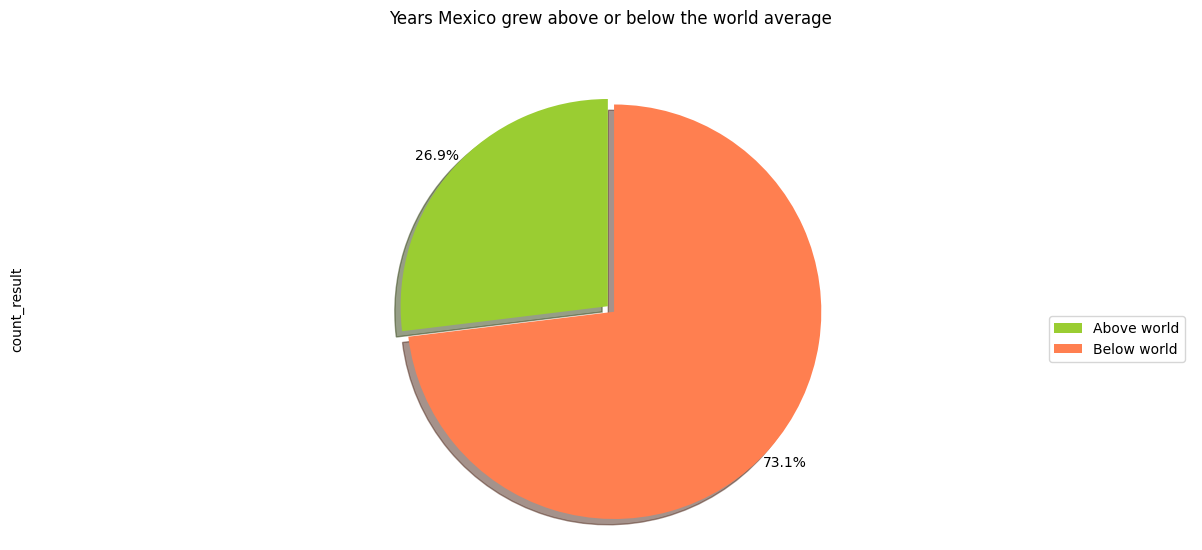

In [33]:
explode_list=[0.03,0.01]
colors=['yellowgreen','coral']

result_counts['count_result'].plot(kind='pie',
                                   figsize=(15,6),
                                   autopct='%1.1f%%',
                                   startangle=90,
                                   shadow=True,
                                   labels=None,
                                   pctdistance=1.1,
                                   explode = explode_list,
                                   colors = colors
                                   )
plt.axis('equal')
plt.legend(labels=result_counts.result,
           bbox_to_anchor = (1,0.5)
           )
plt.title('Years Mexico grew above or below the world average', y=1.1)
plt.show()

<details open>
<summary><strong>Insights:</strong></summary>

1. Mexico grew faster than the world in only 7 of 26 years, approximately 26.9%.

2. In the other 19 years, 73.1%, Mexico grew below the world average.

</details>

# [RQ 8: Can a country's average growth in the 2000s predict its average growth in the 2010s?](#scrollTo=aToc000000&line=21&uniqifier=1)
**Question:** Can the average growth of a country in the 2000s help predict its average growth in the 2010s?

**Model:** avg_late = intercept + slope * (avg_early)

- **Dependent variable (Y):** avg_late, the average GDP growth (%) from 2010 to 2019.
- **Independent variable (X):** avg_early, the average GDP growth (%) from 2000 to 2009.

**Why this figure:** A scatter plot shows the relationship between two numerical variables, and the line shows the prediction of the model.

In [34]:
cdf['avg_early']=cdf.loc[:,'2000':'2009'].mean(axis=1)
cdf['avg_late']=cdf.loc[:,'2010':'2019'].mean(axis=1)
cdf[['country','avg_early','avg_late']].head()

,country,avg_early,avg_late
4,Angola,8.761500,2.573292
5,Albania,5.880222,2.552207
6,Andorra,3.392160,0.109360
9,Argentina,2.581946,1.384672
10,Armenia,8.680000,4.470000


In [43]:
#Fit the model#
slope, intercept = np.polyfit(cdf['avg_early'], cdf['avg_late'], 1)
r = cdf['avg_early'].corr(cdf['avg_late'])
r_squared = r**2

results=pd.DataFrame({'Value': [intercept, slope, r, r_squared]},
                     index=['Intercept','Slope','Correlation (r)','R squared'])
results.round(3)

,Value
Intercept,2.722
Slope,0.175
Correlation (r),0.218
R squared,0.047


### Residuals and outliers:

A residual is real value minus the predicted value. An outlier is a country whose residual is very far from the rest (1.5 * IQR).

In [36]:
cdf['resid']=cdf['avg_late'] - (intercept + slope*cdf['avg_early'])
cdf['resid'].describe()

,resid
count,1.830000e+02
mean,-1.494858e-15
std,2.243675e+00
min,-1.147609e+01
25%,-1.370308e+00
50%,-1.410696e-01
75%,1.341766e+00
max,5.640546e+00


In [37]:
q1=cdf['resid'].quantile(0.25)
q3=cdf['resid'].quantile(0.75)
iqr=q3 - q1
low=q1 - 1.5*iqr
high=q3 + 1.5*iqr

outliers=cdf[(cdf['resid'] < low) | (cdf['resid'] > high)]
outliers[['country','avg_early','avg_late','resid']].round(2)

,country,avg_early,avg_late,resid
72,Ethiopia,8.10,9.78,5.64
88,Equatorial Guinea,21.19,-3.31,-9.74
254,"Venezuela, RB",3.97,-8.06,-11.48


In [38]:
no_out=cdf.drop(outliers.index)
r_no_out=no_out['avg_early'].corr(no_out['avg_late'])
r_no_out**2

np.float64(0.139062633503449)

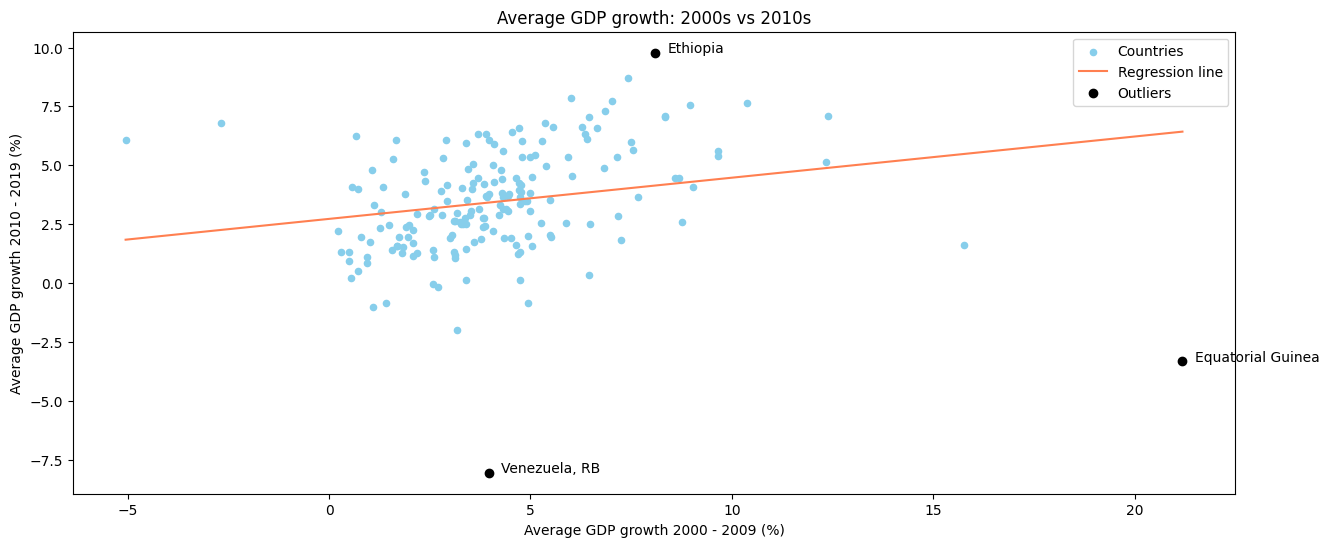

In [39]:
cdf.plot(x='avg_early',
         y='avg_late',
         kind='scatter',
         figsize=(15,6),
         color='skyblue',
         label='Countries'
         )

x_line=[cdf['avg_early'].min(), cdf['avg_early'].max()]
y_line=[intercept + slope*x_line[0], intercept + slope*x_line[1]]
plt.plot(x_line, y_line, color='coral', label='Regression line')

plt.scatter(outliers['avg_early'], outliers['avg_late'], color='black', label='Outliers')
for i in outliers.index:
  plt.text(outliers.loc[i,'avg_early'] + 0.3, outliers.loc[i,'avg_late'], outliers.loc[i,'country'])

plt.legend()
plt.title('Average GDP growth: 2000s vs 2010s')
plt.xlabel('Average GDP growth 2000 - 2009 (%)')
plt.ylabel('Average GDP growth 2010 - 2019 (%)')
plt.show()

### Prediction

Type the % that a country grew on average in the 2000s:

In [55]:
example=input("Type in the % of growth")

example1=float(example)
prediction=intercept + slope*example1
round(prediction,2)

Type in the % of growth5


np.float64(3.6)

### How to read the model

- **R squared (0.047):** the 2000s explain only about 5% of the differences between countries in the 2010s. The other 95% depends on other factors.
- **Residuals:** the average residual is 0 and the typical error is about 2.2 pp, so predictions can be far from the real value.
- **Outliers:** Ethiopia, Equatorial Guinea and Venezuela are far from the line. Without them R squared rises to 0.139, which is still low.

<details open>
<summary><strong>Insights:</strong></summary>

1. Growth in the 2000s is a weak predictor of growth in the 2010s. Each extra point of growth in the 2000s has only 0.18 more points in the 2010s, and the model explains about 5% of the differences.

2. A country that grew 5% in the 2000s is predicted to grow about 3.6% in the 2010s, with a typical error of about 2.2 pp. For policymakers and investors this means past growth alone is not a reliable guide for the future.

</details>

## [Final Conclusions](#scrollTo=aToc000000&line=21&uniqifier=1)

- **Most important findings:** The growth gap between income groups narrowed, but mainly because low, lower middle and upper middle income economies slowed down, while High income stayed around 2%. Crises hit many countries at the same time, especially 2020 (147 of 183 countries going down) and 2009 (about 90).
- **Patterns across studies:** Growth is very different across regions (South Asia fastest, Latin America & Caribbean the most volatile) and across countries (Guyana at about 10.8%, while the typical country grew about 3.4% in 2024). Mexico grew below the world in 19 of 26 years.
- **Unexpected result:** Poorer economies are not clearly catching up faster. The gap narrowed and fast growth did not last, because growth in the 2000s explains only about 5% of growth in the 2010s.
- **Practical conclusion:** Past growth alone is a weak guide for the future. Policymakers and investors need more information than the growth history of a country.
- **Limitations:** The data compares growth rates, not income levels. Countries with missing years were removed (231 of 266 rows kept), groups include high-income countries, and 2025 may still be revised. The results are descriptive, not proof of causes, and the regression uses only one explanatory variable.
- **Future work:** Add GDP per capita (income levels) to test catch-up directly, add more explanatory variables to the regression, and use the full 1960 to 2025 data.